# EX7 - Generate Synthetic Images using a GAN

# PART A: DATASET PREPARATION AND IMAGE PREPROCESSING

In [1]:
print("24BAD004")
print("K ADHITHYA")

24BAD004
K ADHITHYA


In [2]:
# Part A - import libraries
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

ROLL_NO = "24BAD004"
print("Roll No:", ROLL_NO)
print("TensorFlow version:", tf.__version__)

Roll No: 24BAD004
TensorFlow version: 2.21.0


In [3]:
# Part A - load the MNIST dataset
# labels are not needed for a GAN, but loading them anyway
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()
print("Roll No:", ROLL_NO)
print("MNIST loaded successfully")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Roll No: 24BAD004
MNIST loaded successfully


In [4]:
# Part A - number of images and image dimensions
print("Roll No:", ROLL_NO)
print("Training images shape:", train_images.shape)
print("Test images shape:", test_images.shape)
print("Number of training images:", train_images.shape[0])
print("Number of test images:", test_images.shape[0])
print("Image size:", train_images.shape[1:])
print("Pixel range:", train_images.min(), "to", train_images.max())

Roll No: 24BAD004
Training images shape: (60000, 28, 28)
Test images shape: (10000, 28, 28)
Number of training images: 60000
Number of test images: 10000
Image size: (28, 28)
Pixel range: 0 to 255


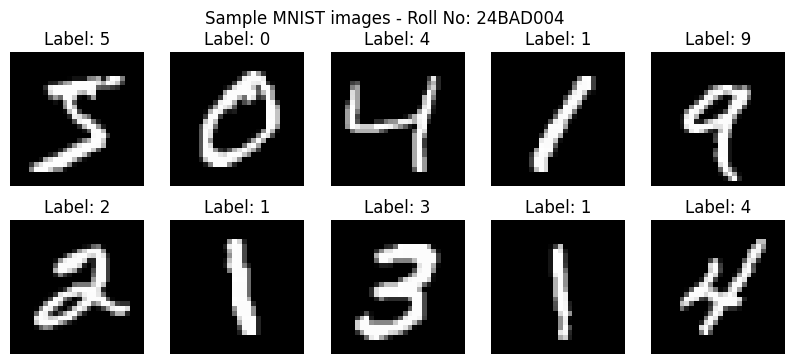

In [5]:
# Part A - display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images[i], cmap='gray')
    plt.title("Label: " + str(train_labels[i]))
    plt.axis('off')
plt.suptitle("Sample MNIST images - Roll No: " + ROLL_NO)
plt.show()

In [6]:
# Part A - reshape and normalize
# reshape to (28, 28, 1) because conv layers need a channel dimension
train_images = train_images.reshape(train_images.shape[0], 28, 28, 1).astype('float32')

# normalize pixels from [0, 255] to [-1, 1] (matches tanh output of generator)
train_images = (train_images - 127.5) / 127.5

print("Roll No:", ROLL_NO)
print("After reshape:", train_images.shape)
print("After normalization -> min:", train_images.min(), "max:", train_images.max())

Roll No: 24BAD004
After reshape: (60000, 28, 28, 1)
After normalization -> min: -1.0 max: 1.0


In [7]:
# Part A - data pipeline (shuffle, batch, prefetch)
BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_dataset = tf.data.Dataset.from_tensor_slices(train_images)
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Roll No:", ROLL_NO)
print("Number of batches per epoch:", len(train_dataset))
for batch in train_dataset.take(1):
    print("One batch shape:", batch.shape)

Roll No: 24BAD004
Number of batches per epoch: 235
One batch shape: (256, 28, 28, 1)


# PART B: IMPLEMENTING THE GENERATOR

In [8]:
# Part B - define the generator
NOISE_DIM = 100   # size of the random noise vector

def build_generator():
    model = tf.keras.Sequential(name="Generator_24BAD004")

    # noise vector -> dense layer -> reshape into a small 7x7 feature map
    model.add(layers.Input(shape=(NOISE_DIM,)))
    model.add(layers.Dense(7 * 7 * 256, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((7, 7, 256)))

    # 7x7 -> 7x7
    model.add(layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # 7x7 -> 14x14
    model.add(layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # 14x14 -> 28x28, tanh gives output in [-1, 1]
    model.add(layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same',
                                     use_bias=False, activation='tanh'))
    return model

generator = build_generator()
print("Roll No:", ROLL_NO)
print("Generator created")

Roll No: 24BAD004
Generator created


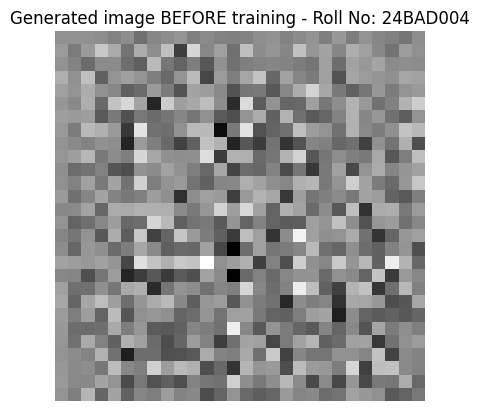

Noise shape: (1, 100) -> Generated image shape: (1, 28, 28, 1)


In [9]:
# Part B - generate an image from random noise (before training)
noise = tf.random.normal([1, NOISE_DIM])
generated_image = generator(noise, training=False)

plt.imshow(generated_image[0, :, :, 0], cmap='gray')
plt.title("Generated image BEFORE training - Roll No: " + ROLL_NO)
plt.axis('off')
plt.show()
print("Noise shape:", noise.shape, "-> Generated image shape:", generated_image.shape)

In [10]:
# Part B - generator architecture and summary
print("Roll No:", ROLL_NO)
generator.summary()

Roll No: 24BAD004


Model: "Generator_24BAD004"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

# PART C: IMPLEMENTING THE DISCRIMINATOR AND GAN MODEL

In [11]:
# Part C - define the discriminator
def build_discriminator():
    model = tf.keras.Sequential(name="Discriminator_24BAD004")

    # conv layers to extract features from the image
    model.add(layers.Input(shape=(28, 28, 1)))
    model.add(layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))   # dropout so the discriminator doesn't get too strong

    model.add(layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1, activation='sigmoid'))   # 1 = real, 0 = fake
    return model

discriminator = build_discriminator()
print("Roll No:", ROLL_NO)
print("Discriminator created")

Roll No: 24BAD004
Discriminator created


In [12]:
# Part C - compile the discriminator (Adam + binary cross-entropy)
discriminator.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                      loss='binary_crossentropy',
                      metrics=['accuracy'])

# test the discriminator on the untrained generator's image
decision = discriminator(generated_image)
print("Roll No:", ROLL_NO)
print("Discriminator output for fake image (before training):", decision.numpy())

Roll No: 24BAD004
Discriminator output for fake image (before training): [[0.5003259]]


In [13]:
# Part C - combine generator and discriminator into the GAN
# discriminator is frozen here, so only the generator learns through this model
discriminator.trainable = False
gan = tf.keras.Sequential([generator, discriminator], name="GAN_24BAD004")
gan.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='binary_crossentropy')
print("Roll No:", ROLL_NO)
print("GAN model created")

Roll No: 24BAD004
GAN model created


In [14]:
# Part C - generator summary
print("Roll No:", ROLL_NO)
generator.summary()

Roll No: 24BAD004


Model: "Generator_24BAD004"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [15]:
# Part C - discriminator summary
print("Roll No:", ROLL_NO)
discriminator.summary()

Roll No: 24BAD004


Model: "Discriminator_24BAD004"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 212,865 (831.50 KB)

In [16]:
# Part C - GAN summary
print("Roll No:", ROLL_NO)
gan.summary()

Roll No: 24BAD004


Model: "GAN_24BAD004"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator_24BAD004 (Sequential) │ (None, 28, 28, 1)      │     2,330,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator_24BAD004          │ (None, 1)              │       212,865 │
│ (Sequential)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,543,809 (9.70 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 238,337 (931.00 KB)

# PART D: GAN TRAINING AND SYNTHETIC IMAGE GENERATION

In [17]:
# Part D - settings, fixed noise, fresh models and optimizers
import os
import time

EPOCHS = 50
NUM_EXAMPLES = 16
SAVE_EVERY = 10   # show/save generated images every 10 epochs

# fixed noise so we can compare the same images across epochs
seed = tf.random.normal([NUM_EXAMPLES, NOISE_DIM])

# fresh generator and discriminator for training
generator = build_generator()
discriminator = build_discriminator()

gen_optimizer = tf.keras.optimizers.Adam(1e-4)
disc_optimizer = tf.keras.optimizers.Adam(1e-4)

print("Roll No:", ROLL_NO)
print("Ready to train for", EPOCHS, "epochs")

Roll No: 24BAD004
Ready to train for 50 epochs


In [18]:
# Part D - loss functions
bce = tf.keras.losses.BinaryCrossentropy()

def discriminator_loss(real_output, fake_output):
    real_loss = bce(tf.ones_like(real_output), real_output)    # real -> 1
    fake_loss = bce(tf.zeros_like(fake_output), fake_output)   # fake -> 0
    return real_loss + fake_loss

def generator_loss(fake_output):
    # generator wants discriminator to say 1 (real) for its fake images
    return bce(tf.ones_like(fake_output), fake_output)

print("Roll No:", ROLL_NO)
print("Loss functions defined")

Roll No: 24BAD004
Loss functions defined


In [19]:
# Part D - one training step
@tf.function
def train_step(real_images):
    noise = tf.random.normal([tf.shape(real_images)[0], NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = generator_loss(fake_output)
        d_loss = discriminator_loss(real_output, fake_output)

    gen_grads = gen_tape.gradient(g_loss, generator.trainable_variables)
    disc_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)

    gen_optimizer.apply_gradients(zip(gen_grads, generator.trainable_variables))
    disc_optimizer.apply_gradients(zip(disc_grads, discriminator.trainable_variables))
    return g_loss, d_loss

print("Roll No:", ROLL_NO)
print("train_step defined")

Roll No: 24BAD004
train_step defined


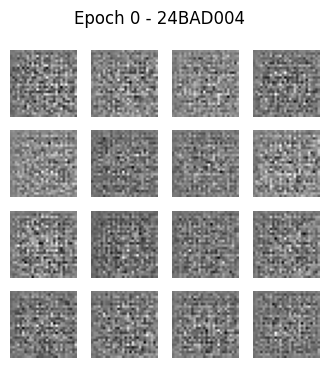

In [20]:
# Part D - helper function to show and save generated images
def show_and_save(model, epoch, test_input, folder="gan_outputs"):
    os.makedirs(folder, exist_ok=True)
    preds = model(test_input, training=False)
    fig = plt.figure(figsize=(4, 4))
    for i in range(preds.shape[0]):
        plt.subplot(4, 4, i + 1)
        plt.imshow(preds[i, :, :, 0] * 127.5 + 127.5, cmap='gray')   # back to 0-255
        plt.axis('off')
    plt.suptitle("Epoch " + str(epoch) + " - " + ROLL_NO)
    plt.savefig(folder + "/image_at_epoch_" + str(epoch).zfill(3) + ".png")
    plt.show()

# images at epoch 0 (before training) for comparison
show_and_save(generator, 0, seed)

Roll No: 24BAD004
Epoch 1/50 | Gen loss: 0.9218 | Disc loss: 0.8527 | Time: 21.6s


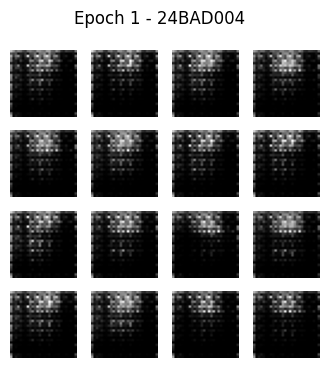

Epoch 2/50 | Gen loss: 0.7921 | Disc loss: 1.3026 | Time: 12.6s
Epoch 3/50 | Gen loss: 1.0170 | Disc loss: 1.0782 | Time: 12.8s
Epoch 4/50 | Gen loss: 0.8994 | Disc loss: 1.2427 | Time: 13.2s
Epoch 5/50 | Gen loss: 0.9104 | Disc loss: 1.2253 | Time: 13.3s
Epoch 6/50 | Gen loss: 0.9312 | Disc loss: 1.1831 | Time: 13.5s
Epoch 7/50 | Gen loss: 0.8371 | Disc loss: 1.3258 | Time: 13.8s
Epoch 8/50 | Gen loss: 0.8449 | Disc loss: 1.2968 | Time: 14.0s
Epoch 9/50 | Gen loss: 0.8610 | Disc loss: 1.2531 | Time: 14.1s
Epoch 10/50 | Gen loss: 0.8678 | Disc loss: 1.2683 | Time: 14.2s


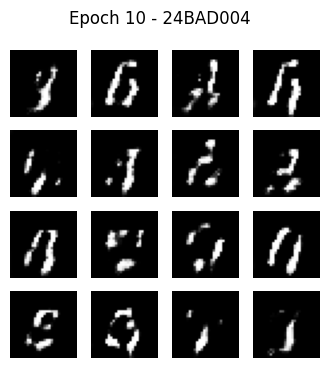

Epoch 11/50 | Gen loss: 0.9055 | Disc loss: 1.2378 | Time: 14.1s
Epoch 12/50 | Gen loss: 0.9705 | Disc loss: 1.1678 | Time: 14.1s
Epoch 13/50 | Gen loss: 0.9816 | Disc loss: 1.2176 | Time: 14.0s
Epoch 14/50 | Gen loss: 0.9882 | Disc loss: 1.1535 | Time: 14.0s
Epoch 15/50 | Gen loss: 1.0488 | Disc loss: 1.1415 | Time: 14.1s
Epoch 16/50 | Gen loss: 1.1432 | Disc loss: 1.0814 | Time: 14.2s
Epoch 17/50 | Gen loss: 1.1501 | Disc loss: 1.0545 | Time: 14.1s
Epoch 18/50 | Gen loss: 1.1470 | Disc loss: 1.1045 | Time: 14.1s
Epoch 19/50 | Gen loss: 1.1739 | Disc loss: 1.0813 | Time: 14.1s
Epoch 20/50 | Gen loss: 1.2210 | Disc loss: 1.0097 | Time: 14.1s


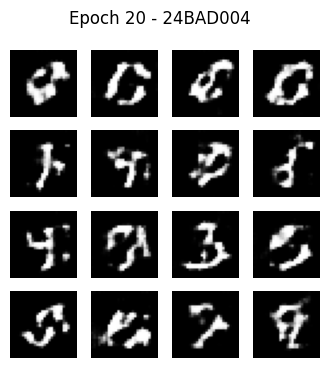

Epoch 21/50 | Gen loss: 1.1315 | Disc loss: 1.0930 | Time: 14.1s
Epoch 22/50 | Gen loss: 1.2152 | Disc loss: 1.0059 | Time: 14.1s
Epoch 23/50 | Gen loss: 1.3427 | Disc loss: 0.9552 | Time: 14.1s
Epoch 24/50 | Gen loss: 1.3120 | Disc loss: 1.0182 | Time: 14.1s
Epoch 25/50 | Gen loss: 1.3466 | Disc loss: 0.9635 | Time: 14.1s
Epoch 26/50 | Gen loss: 1.3344 | Disc loss: 1.0032 | Time: 14.2s
Epoch 27/50 | Gen loss: 1.3365 | Disc loss: 0.9805 | Time: 14.2s
Epoch 28/50 | Gen loss: 1.1918 | Disc loss: 1.0973 | Time: 14.1s
Epoch 29/50 | Gen loss: 1.1884 | Disc loss: 1.1209 | Time: 14.1s
Epoch 30/50 | Gen loss: 1.1576 | Disc loss: 1.1125 | Time: 14.1s


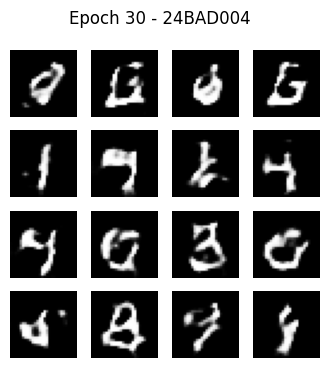

Epoch 31/50 | Gen loss: 1.0848 | Disc loss: 1.1501 | Time: 14.1s
Epoch 32/50 | Gen loss: 1.0420 | Disc loss: 1.1844 | Time: 14.1s
Epoch 33/50 | Gen loss: 1.0511 | Disc loss: 1.1801 | Time: 14.1s
Epoch 34/50 | Gen loss: 1.1056 | Disc loss: 1.1542 | Time: 14.2s
Epoch 35/50 | Gen loss: 1.1220 | Disc loss: 1.1319 | Time: 14.2s
Epoch 36/50 | Gen loss: 1.0368 | Disc loss: 1.1917 | Time: 14.2s
Epoch 37/50 | Gen loss: 0.9659 | Disc loss: 1.2272 | Time: 14.2s
Epoch 38/50 | Gen loss: 0.9776 | Disc loss: 1.2164 | Time: 14.2s
Epoch 39/50 | Gen loss: 1.0856 | Disc loss: 1.1826 | Time: 14.2s
Epoch 40/50 | Gen loss: 1.1159 | Disc loss: 1.1543 | Time: 14.3s


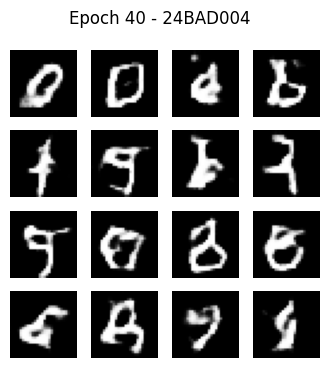

Epoch 41/50 | Gen loss: 1.0603 | Disc loss: 1.1731 | Time: 14.3s
Epoch 42/50 | Gen loss: 0.9846 | Disc loss: 1.2185 | Time: 14.3s
Epoch 43/50 | Gen loss: 0.9509 | Disc loss: 1.2267 | Time: 14.2s
Epoch 44/50 | Gen loss: 0.9416 | Disc loss: 1.2280 | Time: 14.2s
Epoch 45/50 | Gen loss: 0.9531 | Disc loss: 1.2267 | Time: 14.2s
Epoch 46/50 | Gen loss: 1.0471 | Disc loss: 1.1871 | Time: 14.2s
Epoch 47/50 | Gen loss: 1.1082 | Disc loss: 1.1461 | Time: 14.2s
Epoch 48/50 | Gen loss: 1.0237 | Disc loss: 1.1910 | Time: 14.2s
Epoch 49/50 | Gen loss: 0.9765 | Disc loss: 1.2095 | Time: 14.2s
Epoch 50/50 | Gen loss: 1.0060 | Disc loss: 1.2128 | Time: 14.2s


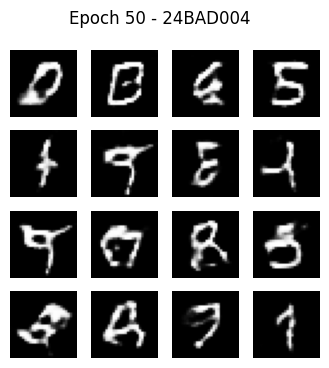

In [21]:
# Part D - training loop (records generator and discriminator loss)
gen_losses = []
disc_losses = []

print("Roll No:", ROLL_NO)
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    g_total, d_total, n = 0.0, 0.0, 0

    for image_batch in train_dataset:
        g_loss, d_loss = train_step(image_batch)
        g_total += float(g_loss)
        d_total += float(d_loss)
        n += 1

    gen_losses.append(g_total / n)
    disc_losses.append(d_total / n)

    print("Epoch %d/%d | Gen loss: %.4f | Disc loss: %.4f | Time: %.1fs"
          % (epoch, EPOCHS, gen_losses[-1], disc_losses[-1], time.time() - start))

    # show generated images at regular intervals
    if epoch % SAVE_EVERY == 0 or epoch == 1:
        show_and_save(generator, epoch, seed)

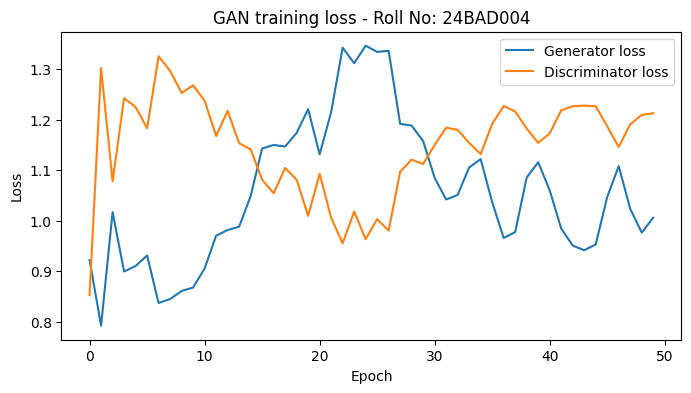

In [22]:
# Part D - plot generator and discriminator loss
plt.figure(figsize=(8, 4))
plt.plot(gen_losses, label="Generator loss")
plt.plot(disc_losses, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN training loss - Roll No: " + ROLL_NO)
plt.legend()
plt.show()

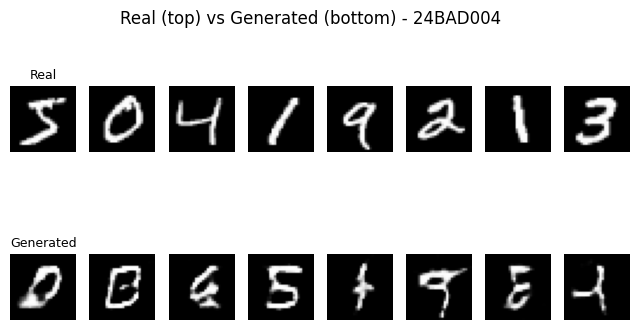

In [23]:
# Part D - compare real images with generated images
real_batch = train_images[:16]
final_fake = generator(seed, training=False).numpy()

plt.figure(figsize=(8, 4))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(real_batch[i, :, :, 0], cmap='gray')
    plt.axis('off')
    if i == 0: plt.title("Real", fontsize=9)
    plt.subplot(2, 8, i + 9)
    plt.imshow(final_fake[i, :, :, 0], cmap='gray')
    plt.axis('off')
    if i == 0: plt.title("Generated", fontsize=9)
plt.suptitle("Real (top) vs Generated (bottom) - " + ROLL_NO)
plt.show()

In [24]:
# Part D - quality and diversity check
# generate 500 images and see how much they differ from each other
many = generator(tf.random.normal([500, NOISE_DIM]), training=False).numpy()
print("Roll No:", ROLL_NO)
print("Std of pixels across 500 generated images:", many.std(axis=0).mean())
print("Std of pixels across 500 real images     :", train_images[:500].std(axis=0).mean())
# if generated std is close to real std, the images are diverse (no mode collapse)

Roll No: 24BAD004
Std of pixels across 500 generated images: 0.32035208
Std of pixels across 500 real images     : 0.37486652


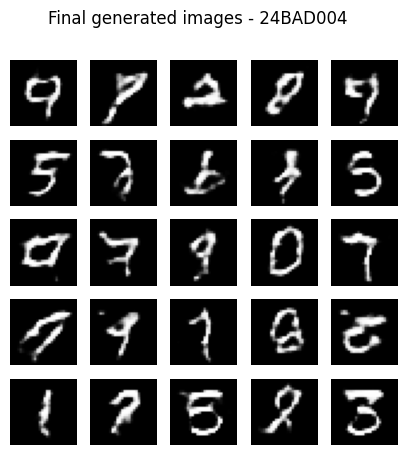

Roll No: 24BAD004
Final images and generator model saved in gan_outputs/


In [25]:
# Part D - save the final generated images and the generator model
os.makedirs("gan_outputs", exist_ok=True)
final_images = generator(tf.random.normal([25, NOISE_DIM]), training=False)

plt.figure(figsize=(5, 5))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(final_images[i, :, :, 0] * 127.5 + 127.5, cmap='gray')
    plt.axis('off')
plt.suptitle("Final generated images - " + ROLL_NO)
plt.savefig("gan_outputs/final_generated_images_" + ROLL_NO + ".png")
plt.show()

generator.save("gan_outputs/generator_final.keras")
print("Roll No:", ROLL_NO)
print("Final images and generator model saved in gan_outputs/")